# HypeCheck — paste a post, test a forecast
**AI + Finance · Nathaniel Wong, Aaden Yick, Alastair Chu · Malvern College Hong Kong**

**Our user:** a trader reading a public X post about a memecoin. **Input:** its text, selected coin and optional earlier public discussion. **Output:** an estimated probability of next-day UP and a research-only return estimate.

The target is the **next complete UTC calendar day, open to close**, not the next 24 hours and not movement caused by this tweet. Wording is trained directly against actual market outcomes, not an AI sentiment label. This is a genuine predictive model, but prediction does not guarantee accuracy.

**Run:** Runtime → Run all. Change the text and coin in **Section 9** and rerun that cell. [Browser input demo](https://adeviwon.github.io/hypecheck/predict.html).

**Bottom line:** these models did not beat the training-majority direction rule. Recent-context and magnitude predictions are experiments, not validated trading signals. The reused archive makes this exploratory. No live X feed is connected.

*This project is a prototype and is not financial advice.*

In [1]:
#@title Automatic environment and verified source setup
import sys,subprocess,json,hashlib,urllib.request
from pathlib import Path
IN_COLAB="google.colab" in sys.modules
if IN_COLAB:
    pins=["numpy==2.5.4","pandas==3.1.1","pyarrow==26.0.1","scikit-learn==1.9.1","requests==2.34.2","ipython==9.18.1"]
    subprocess.run([sys.executable,"-m","pip","install","-q",*pins],check=True)

In [2]:
SETUP_REV='2ce94ac955100ec37968fdfa404e3ae7af8e430b'
SETUP_SHA='48e912fec0f69329b2ed93ef5da6cca4890ec191fa6e84367eece7be2a246cb4'
SOURCE_REV='b81c405871778ec6e92918e3c4243366bf2d5895'
SOURCE_FILES={'tweet_forecast.py': 'd9732560a07ad65cc96fdb07d28b6d1d14dcc8dda06c71014883de2dbb019d4b', 'test_tweet_forecast.py': '7169a72135012012ef3f9710378659b74d57bfbda70e15de7d6ffd524a1e8fe7'}

files={"colab_setup.py":(SETUP_REV,SETUP_SHA),"notebook_support.py":(SETUP_REV,'e5dd57e29724851b18e5bd2ebfb9b226b4bb5a72be36b4144a51503ab2e01e70'),**{n:(SOURCE_REV,h) for n,h in SOURCE_FILES.items()}}
for name,(rev,expected) in files.items():
    url=f"https://raw.githubusercontent.com/adeviwon/hypecheck/{rev}/{name}"
    with urllib.request.urlopen(url,timeout=60) as response:payload=response.read()
    if hashlib.sha256(payload).hexdigest()!=expected:raise ValueError("Changed source: "+name)
    Path(name).write_bytes(payload)
from colab_setup import prepare
prepare()
import numpy as np,pandas as pd
from notebook_support import table,accuracy_chart
import contextlib,io
from tweet_forecast import load,build_examples,split_data,weights,features,train_all,predict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss
print("Environment ready. Actual Colab runtime:",IN_COLAB)

Verified source and market data. Sentiment: verified cache
Environment ready. Actual Colab runtime: False


## 1. Load the data
Original public posts and actual Binance daily market bars for 13 memecoins. No hand-picked bullish/bearish quota. The setup verifies the exact source and data before loading. Price labels are **actual market outcomes**, not model guesses.

In [3]:
raw,posts,prices,panel=load()
examples=build_examples(posts,prices)
print(f"{len(posts):,} original posts; {len(examples):,} eligible post/coin events; {len(prices)} coins.")

1,773 original posts; 1,796 eligible post/coin events; 13 coins.


## 2. Inspect before training
A post can mention multiple coins. Repeated posts on one coin-day share its market outcome; they are not independent tests. Recent discussion includes at most 20 posts in the preceding 24 hours, strictly before the input post becomes available. No later likes, views or price moves are features.

In [4]:
table(examples[["available_at","date","coin","text","context_posts","actual_up"]].head(5),"Real posts and actual market labels")
assert (examples.available_at<examples.date).all()
assert (examples.context_latest.isna()|(examples.context_latest<examples.available_at)).all()
print("Input and context timestamps precede the prediction target.")

Input and context timestamps precede the prediction target.


available_at,date,coin,text,context_posts,actual_up
2024-03-22 04:49:17.553+00:00,2024-03-23 00:00:00+00:00,BOME,Take partial profit fam 🔥 $bome #bome,0,0
2024-03-22 06:29:03.335+00:00,2024-03-23 00:00:00+00:00,DOGE,$doge legit best looking major by a mile atm imo,0,1
2024-03-22 10:29:17.676+00:00,2024-03-23 00:00:00+00:00,DOGE,Bagged some \n\nBeing honest here. I think $doge gonna pull numbers over the coming 3/4 weeks.\n\nTarget 0.45 📸,1,1
2024-03-22 07:19:03.469+00:00,2024-03-23 00:00:00+00:00,FLOKI,The doge of this cycle should go for the next round anytime now IMO.\n\nAfter consolidation comes continuation.\nInvalidation below the horizontal.\n\n$FLOKI,0,1
2024-03-31 00:57:49.542+00:00,2024-04-01 00:00:00+00:00,BONK,Im gonna need $bonk to send like $wif,0,0


## 3. Split chronologically
Shared training/validation/test dates and a one-day purge. Fit vocabularies and coefficients on training only; choose regularisation using validation Brier error. Keep final dates out of fitting. Earlier research examined these dates, so this is **not independent confirmation**.

In [5]:
train,validation,test=[examples[examples.date.isin(p.date.unique())].copy() for p in split_data(panel)]
table(pd.DataFrame([{ "partition":name,"events":len(d),"coin_days":len(d[["date","coin"]].drop_duplicates()),"first":str(d.date.min().date()),"last":str(d.date.max().date())} for name,d in [("train",train),("validation",validation),("test",test)]]))
assert train.date.max()+pd.Timedelta(days=1)<validation.date.min()
assert validation.date.max()+pd.Timedelta(days=1)<test.date.min()

partition,events,coin_days,first,last
train,1451,859,2024-03-23,2025-09-27
validation,71,55,2025-10-02,2026-04-09
test,271,219,2026-04-21,2026-10-20


## 4. Baselines
Always up, training-majority, training prevalence and coin-only. Persistence uses the **last completed UTC day at the posting time**, not the still-unfinished posting day. All methods use exactly the same observed-post test cases. Each coin-day has total weight one divided over its posts.

In [6]:
from tweet_forecast import evaluate
prevalence=np.average(train.actual_up,weights=weights(train))
baselines={"Always up":np.ones(len(test)),"Training majority":np.full(len(test),float(prevalence>=.5)),"Previous completed day":test.previous_completed_day.to_numpy()}
table(pd.DataFrame([{ "method":name,**evaluate(test,p)} for name,p in baselines.items()]))

method,accuracy,brier,post_coin_events,distinct_coin_days,dates
Always up,0.484018,0.515982,271,219,112
Training majority,0.515982,0.484018,271,219,112
Previous completed day,0.488584,0.511416,271,219,112


## 5. Model — actual visible training
Character TF-IDF learns wording patterns; logistic regression learns next-day direction from real price labels. We train separate tweet-only and tweet-plus-context models, with a coin-only control. Transformers are **not fine-tuned** here. Brier error measures probability error; lower is better. The function below is passed into the real training procedure: its `.fit(...)` calls produce the saved model used by the demo.

index,accuracy,brier,post_coin_events,distinct_coin_days,dates
tweet_only,0.492770,0.252036,271.0,219.0,112.0
tweet_and_context,0.450152,0.252587,271.0,219.0,112.0
coin_only,0.506849,0.251359,271.0,219.0,112.0
always_up,0.484018,0.515982,271.0,219.0,112.0
training_majority,0.515982,0.484018,271.0,219.0,112.0
training_prevalence,0.515982,0.249745,271.0,219.0,112.0
previous_completed_day,0.488584,0.511416,271.0,219.0,112.0


index,C,validation_brier
tweet_only,0.1,0.242008
tweet_and_context,0.1,0.242120
coin_only,1.0,0.239291


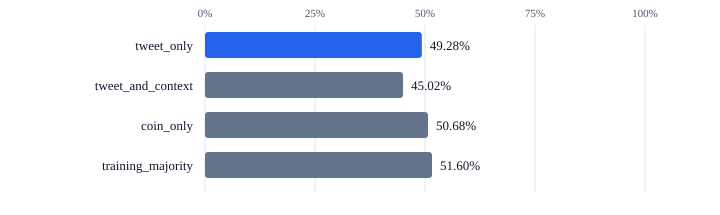

In [7]:
def train_direction(train,validation,context=False,coin_only=False):
    encoder=features(context=context,coin_only=coin_only)
    X_train=encoder.fit_transform(train)
    X_validation=encoder.transform(validation)
    candidates=[]
    for C in [0.01,0.1,1.0]:
        model=LogisticRegression(C=C,max_iter=1500,random_state=42)
        model.fit(X_train,train.actual_up,sample_weight=weights(train))
        p=model.predict_proba(X_validation)[:,1]
        loss=brier_score_loss(validation.actual_up,p,sample_weight=weights(validation))
        candidates.append((float(loss),C,model))
    loss,C,model=min(candidates,key=lambda row:(row[0],row[1]))
    return encoder,model,{"C":C,"validation_brier":loss}

with contextlib.redirect_stdout(io.StringIO()):
    artifact,report=train_all(trainer=train_direction)
table(pd.DataFrame(report["metrics"]).T.reset_index(),"Held-out direction predictions")
table(pd.DataFrame(report["selection"]).T.reset_index(),"Validation-only choices")
accuracy_chart({"metrics":report["metrics"],"primary_model":"tweet_only"},["tweet_only","tweet_and_context","coin_only","training_majority"])

## 6. Where the model goes wrong
Show confident errors, not just convincing examples. These mistakes are not used to tune the model. Probabilities are uncalibrated estimates, not guarantees.

In [8]:
predictions=pd.read_csv("artifacts/tweet-forecast-predictions.csv")
wrong=predictions[(predictions.tweet_only>=.5)!=predictions.actual_up].copy()
wrong["confidence"]=(wrong.tweet_only-.5).abs()
table(wrong.nlargest(5,"confidence")[["date","coin","actual_up","tweet_only","log_return"]])

date,coin,actual_up,tweet_only,log_return
2026-08-23 00:00:00+00:00,WIF,1,0.416740,0.033680
2026-08-28 00:00:00+00:00,TRUMP,1,0.423574,0.071188
2026-08-22 00:00:00+00:00,TRUMP,1,0.423981,0.243492
2026-08-22 00:00:00+00:00,TRUMP,1,0.425067,0.243492
2026-07-02 00:00:00+00:00,TRUMP,1,0.425206,0.019395


## 7. Our addition — public discussion context
A separate model can use preceding public discussion as well as the input post. This tests whether broader wording context contributes, rather than assuming a tweet acts alone. No context supplied means the separately trained **tweet-only** model is used. Texts must already be public at prediction time; the app does not fetch X automatically.

In [9]:
table(pd.DataFrame(report["metrics"]).T.reset_index())
print("Paired date-block accuracy differences vs coin-only:",report["paired_accuracy_vs_coin_only"])

Paired date-block accuracy differences vs coin-only: {'tweet_only': {'mean': -0.014079147640791476, 'interval95': [-0.08559873617693523, 0.052507102272727244], 'method': '1000 paired circular seven-observed-date block resamples; coins kept together'}, 'tweet_and_context': {'mean': -0.056697108066971084, 'interval95': [-0.12041859567901235, 0.006525755400601582], 'method': '1000 paired circular seven-observed-date block resamples; coins kept together'}}


index,accuracy,brier,post_coin_events,distinct_coin_days,dates
tweet_only,0.492770,0.252036,271.0,219.0,112.0
tweet_and_context,0.450152,0.252587,271.0,219.0,112.0
coin_only,0.506849,0.251359,271.0,219.0,112.0
always_up,0.484018,0.515982,271.0,219.0,112.0
training_majority,0.515982,0.484018,271.0,219.0,112.0
training_prevalence,0.515982,0.249745,271.0,219.0,112.0
previous_completed_day,0.488584,0.511416,271.0,219.0,112.0


## 8. How much movement? A separate return experiment
A ridge regression learns actual next-day log returns, with training-only extreme-value clipping. Its output estimates the **whole coin return**, not the effect attributable to this tweet. Compare error with a constant trained without text; a larger error is worse. This head did not beat that baseline and must not be presented as a useful magnitude predictor.

In [10]:
table(pd.DataFrame(report["return_metrics"]).T.reset_index())
print("Units: percentage-point mean absolute error; lower is better.")

Units: percentage-point mean absolute error; lower is better.


index,mae_percentage_points
tweet_only,3.249051
tweet_and_context,3.230860
coin_only,3.155305
training_constant,3.164187


## 9. The demo — enter a public tweet
Edit the input fields and run this cell. The supplied sentence is an **illustrative editable input**, not a selected successful test. Inference uses the saved weights actually trained above. An estimated probability change relative to coin-only is a model comparison, **not causal impact**.

In [11]:
#@title Paste a public post and run the trained forecast
TWEET="DOGE is breaking resistance with increasing trading volume." #@param {type:"string"}
COIN="DOGE" #@param ["DOGE","SHIB","PEPE","BONK","FLOKI","WIF","TRUMP","NEIRO","PENGU","PNUT","TURBO","BOME","MEME"]
RECENT_PUBLIC_POSTS="" #@param {type:"string"}
result=predict(TWEET,COIN,RECENT_PUBLIC_POSTS,artifact=artifact)
table(pd.DataFrame([{"Output":k,"Value":str(v)} for k,v in result.items()]))

Output,Value
coin,DOGE
forecast_window,"Next complete UTC calendar day, open to close; not next 24 hours"
probability_up,0.4773849124541175
direction,DOWN / FLAT
estimated_return_percent,1.0729532385916993
change_vs_coin_baseline_percentage_points,-0.26827332708751483
context_mode,tweet_only
historical_direction_accuracy,0.49277016742770163
historical_coin_baseline_accuracy,0.5068493150684932
warning,"Exploratory estimate, not proven trading skill, calibrated certainty, or this tweet’s causal price impact. Context must already be public before the forecast. No live X feed is connected."


## 10. Results and what a trader can conclude
The model produces predictions but has not demonstrated an edge over simple baselines. Do **not** use a bullish model output as an independently justified reason to trade. An honest negative finding helps challenge misplaced confidence in social posts; it is not a profitable trading system.

The evaluation is sparse, retrospective and reused. Neither accuracy nor a return estimate accounts for fees, slippage or trade execution. Public post text can be misleading or sarcastic. We have not independently calibrated probabilities, collected a complete feed, established causation or tested a prospective deployment.

In [12]:
for filename in ["test_tweet_forecast.py"]:
    completed=subprocess.run([sys.executable,filename],text=True,stdout=subprocess.PIPE,stderr=subprocess.STDOUT)
    print(completed.stdout);completed.check_returncode()
print("Training outputs saved as safe JSON; no pickled estimator. Actual Colab:",IN_COLAB)

........
----------------------------------------------------------------------
Ran 8 tests in 9.236s

OK

Training outputs saved as safe JSON; no pickled estimator. Actual Colab: False


## 11. Sources and responsibility
- Public original-post archive: Stephan Akkerman, financial-tweets-crypto on Hugging Face, pinned revision and hash in pipeline.py. Text is not independently human-verified sentiment ground truth.
- Binance daily spot market bars, frozen and hash-checked in expanded_inputs.py. Third-party terms remain applicable.
- scikit-learn, NumPy, pandas, PyArrow and Requests. Raw wording models here use TF-IDF, logistic regression and ridge regression; they do not fine-tune a pretrained transformer.
- Veritas AI Finance brief and sample submission structure. Hermes Agent/OpenAI coding assistance; the team must understand and explain all work.

This project is a prototype and is not financial advice.